# 01 - Kalman filter for a drifting hedge ratio (synthetic data)

A fixed OLS hedge ratio assumes the relationship between two assets never changes. In practice it drifts. Here I treat the hedge ratio $\beta_t$ as a hidden state that follows a random walk, and use a Kalman filter to update it every day.

Before touching real prices I simulate data where I know the true $\beta_t$, so I can check that the filter actually tracks it.

**Model**

$$y_t = \beta_t x_t + \epsilon_t, \quad \epsilon_t \sim N(0, R)$$
$$\beta_t = \beta_{t-1} + w_t, \quad w_t \sim N(0, Q)$$

**Intuition:** each day I ask how sure I am about my current $\beta$, and how noisy today's observation is. If I'm unsure and the data is clean, I trust the data. If I'm sure and the data is noisy, I mostly ignore it. The Kalman gain is that trust weight.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
num_days = 500
true_beta_start = 1.5
true_process_std = 0.01        # how much the true beta drifts each day
true_measurement_std = 1.0     # noise of y around beta * x

# what the filter assumes about the noise (it never sees the true values)
process_noise_Q = 0.01 ** 2
measurement_noise_R = 1.0 ** 2
initial_beta_guess = 0.0       # wrong on purpose, to see it recover
initial_uncertainty_P = 1.0    # big, because we have no idea yet

random_generator = np.random.default_rng(seed=42)

## Simulate the data

`x` has to move around, otherwise $\beta$ can't be identified from $y = \beta x$. The true $\beta$ is a random walk, which is the same model the filter assumes.

In [3]:
x_prices = 100 + np.cumsum(random_generator.normal(0, 1.0, size=num_days))

beta_changes = random_generator.normal(0, true_process_std, size=num_days)
true_beta = true_beta_start + np.cumsum(beta_changes)

measurement_noise = random_generator.normal(0, true_measurement_std, size=num_days)
y_prices = true_beta * x_prices + measurement_noise

## Run the filter

Each day has a predict step and an update step.

- **Predict:** $\hat\beta_{t|t-1} = \hat\beta_{t-1}$ and $P_{t|t-1} = P_{t-1} + Q$
- **Innovation:** $e_t = y_t - x_t \hat\beta_{t|t-1}$
- **Innovation variance:** $S_t = x_t^2 P_{t|t-1} + R$
- **Gain:** $K_t = P_{t|t-1} x_t / S_t$
- **Update:** $\hat\beta_t = \hat\beta_{t|t-1} + K_t e_t$ and $P_t = (1 - K_t x_t) P_{t|t-1}$

The innovation $e_t$ is the prediction error. Later it becomes the spread I trade.

In [4]:
estimated_beta = np.zeros(num_days)
estimated_P = np.zeros(num_days)
innovations = np.zeros(num_days)

beta_previous = initial_beta_guess
P_previous = initial_uncertainty_P

for day in range(num_days):
    x_today = x_prices[day]
    y_today = y_prices[day]

    # predict: beta is a random walk, so best guess is yesterday's beta,
    # but we are a bit less sure because it could have moved
    beta_predicted = beta_previous
    P_predicted = P_previous + process_noise_Q

    # how wrong was the prediction
    innovation = y_today - x_today * beta_predicted

    # how big a surprise we expect: uncertainty in beta (scaled by x) + noise
    innovation_variance = x_today ** 2 * P_predicted + measurement_noise_R

    # kalman gain: how much of the surprise we blame on beta having moved
    kalman_gain = P_predicted * x_today / innovation_variance

    # update
    beta_updated = beta_predicted + kalman_gain * innovation
    P_updated = (1 - kalman_gain * x_today) * P_predicted

    estimated_beta[day] = beta_updated
    estimated_P[day] = P_updated
    innovations[day] = innovation

    beta_previous = beta_updated
    P_previous = P_updated

## Compare with a static OLS beta

I skip the first 50 days so the deliberately bad initial guess doesn't dominate the error.

In [5]:
static_ols_beta = np.sum(x_prices * y_prices) / np.sum(x_prices ** 2)

kalman_error = np.mean(np.abs(estimated_beta[50:] - true_beta[50:]))
static_error = np.mean(np.abs(static_ols_beta - true_beta[50:]))
print("mean abs error in beta (after day 50)")
print(f"  kalman: {kalman_error:.4f}")
print(f"  static ols: {static_error:.4f}")

mean abs error in beta (after day 50)
  kalman: 0.0071
  static ols: 0.0709


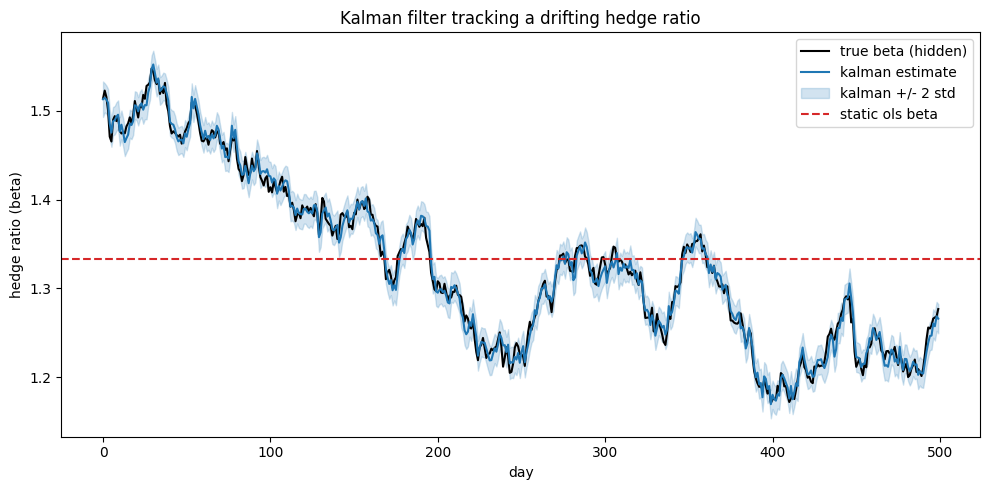

In [6]:
beta_std = np.sqrt(estimated_P)

plt.figure(figsize=(10, 5))
plt.plot(true_beta, label="true beta (hidden)", color="black")
plt.plot(estimated_beta, label="kalman estimate", color="tab:blue")
plt.fill_between(range(num_days),
                 estimated_beta - 2 * beta_std,
                 estimated_beta + 2 * beta_std,
                 color="tab:blue", alpha=0.2, label="kalman +/- 2 std")
plt.axhline(static_ols_beta, color="tab:red", linestyle="--", label="static ols beta")
plt.xlabel("day")
plt.ylabel("hedge ratio (beta)")
plt.title("Kalman filter tracking a drifting hedge ratio")
plt.legend()
plt.tight_layout()
plt.show()

## Notes

- The filter beats static OLS here partly because I gave it the true Q and R. On real data I won't know them, so tuning Q is the hard part.
- Static OLS sits near the middle of the true path: right on average, wrong on almost every day.

**Next:** try different values of Q and R, then extend the state to include an intercept.